# Random forest regression

Nate's workspace for random forest regression experiments.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Make the shared project code accessible
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.config import SPLIT_SEED
from src.data import load_data, create_dev_test_split
from src.evaluation import regression_metrics

# Load the shared dataset
df = load_data()

# Create the shared development/test split
X_dev, X_test, y_dev, y_test = create_dev_test_split(df)

print("Dataset shape:", df.shape)
print("Development features:", X_dev.shape)
print("Test features:", X_test.shape)
print("Development targets:", y_dev.shape)
print("Test targets:", y_test.shape)

Dataset shape: (768, 10)
Development features: (614, 8)
Test features: (154, 8)
Development targets: (614, 2)
Test targets: (154, 2)


In [2]:
# Create a training/validation split from development data
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    random_state=SPLIT_SEED
)

# Check the sizes of each dataset
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training targets:", y_train.shape)
print("Validation targets:", y_val.shape)

Training features: (491, 8)
Validation features: (123, 8)
Training targets: (491, 2)
Validation targets: (123, 2)


In [3]:
# Train an initial Random Forest model for heating load
rf_heating = RandomForestRegressor(
    n_estimators=100,
    random_state=SPLIT_SEED,
    n_jobs=-1
)

rf_heating.fit(X_train, y_train.iloc[:, 0])

# Train an initial Random Forest model for cooling load
rf_cooling = RandomForestRegressor(
    n_estimators=100,
    random_state=SPLIT_SEED,
    n_jobs=-1
)

rf_cooling.fit(X_train, y_train.iloc[:, 1])

print("Heating load Random Forest trained successfully!")
print("Cooling load Random Forest trained successfully!")

Heating load Random Forest trained successfully!
Cooling load Random Forest trained successfully!


In [4]:
# Predict heating and cooling loads using validation data
heating_predictions = rf_heating.predict(X_val)
cooling_predictions = rf_cooling.predict(X_val)

# Evaluate heating load predictions
heating_mae = np.mean(np.abs(
    y_val.iloc[:, 0] - heating_predictions
))
heating_rmse = np.sqrt(np.mean(
    (y_val.iloc[:, 0] - heating_predictions) ** 2
))

# Evaluate cooling load predictions
cooling_mae = np.mean(np.abs(
    y_val.iloc[:, 1] - cooling_predictions
))
cooling_rmse = np.sqrt(np.mean(
    (y_val.iloc[:, 1] - cooling_predictions) ** 2
))

# Calculate R-squared values
from sklearn.metrics import r2_score

heating_r2 = r2_score(y_val.iloc[:, 0], heating_predictions)
cooling_r2 = r2_score(y_val.iloc[:, 1], cooling_predictions)

# Display results
print("RANDOM FOREST VALIDATION RESULTS")
print("--------------------------------")

print("\nHeating Load:")
print(f"MAE:  {heating_mae:.4f}")
print(f"RMSE: {heating_rmse:.4f}")
print(f"R²:   {heating_r2:.4f}")

print("\nCooling Load:")
print(f"MAE:  {cooling_mae:.4f}")
print(f"RMSE: {cooling_rmse:.4f}")
print(f"R²:   {cooling_r2:.4f}")

RANDOM FOREST VALIDATION RESULTS
--------------------------------

Heating Load:
MAE:  0.3294
RMSE: 0.5298
R²:   0.9974

Cooling Load:
MAE:  1.1330
RMSE: 1.9396
R²:   0.9595


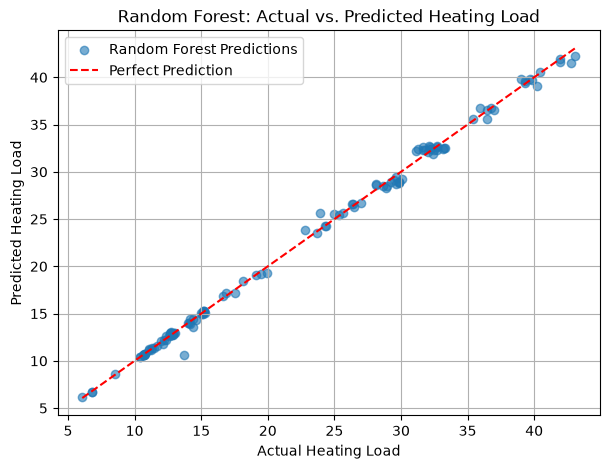

In [5]:
import matplotlib.pyplot as plt

# Plot actual vs predicted heating loads
plt.figure(figsize=(7, 5))

plt.scatter(
    y_val.iloc[:, 0],
    heating_predictions,
    alpha=0.6,
    label="Random Forest Predictions"
)

# Perfect prediction reference line
min_val = min(y_val.iloc[:, 0].min(), heating_predictions.min())
max_val = max(y_val.iloc[:, 0].max(), heating_predictions.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Heating Load")
plt.ylabel("Predicted Heating Load")
plt.title("Random Forest: Actual vs. Predicted Heating Load")
plt.legend()
plt.grid(True)

plt.show()

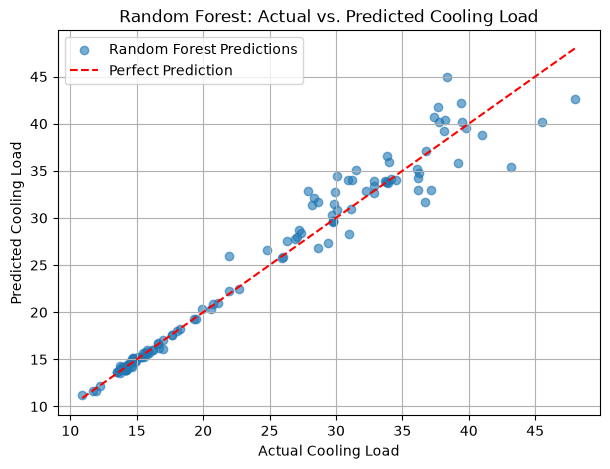

In [6]:
# Plot actual vs predicted cooling loads
plt.figure(figsize=(7, 5))

plt.scatter(
    y_val.iloc[:, 1],
    cooling_predictions,
    alpha=0.6,
    label="Random Forest Predictions"
)

# Perfect prediction reference line
min_val = min(y_val.iloc[:, 1].min(), cooling_predictions.min())
max_val = max(y_val.iloc[:, 1].max(), cooling_predictions.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Cooling Load")
plt.ylabel("Predicted Cooling Load")
plt.title("Random Forest: Actual vs. Predicted Cooling Load")
plt.legend()
plt.grid(True)

plt.show()

In [7]:
# Create output folders if needed
figures_dir = project_root / "results" / "figures"
tables_dir = project_root / "results" / "tables"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Save Random Forest validation results
rf_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Target": "Heating Load",
        "MAE": heating_mae,
        "RMSE": heating_rmse,
        "R2": heating_r2
    },
    {
        "Model": "Random Forest",
        "Target": "Cooling Load",
        "MAE": cooling_mae,
        "RMSE": cooling_rmse,
        "R2": cooling_r2
    }
])

rf_results.to_csv(
    tables_dir / "random_forest_validation_results.csv",
    index=False
)

# Save actual vs predicted graphs
for target, actual, predicted in [
    ("heating", y_val.iloc[:, 0], heating_predictions),
    ("cooling", y_val.iloc[:, 1], cooling_predictions)
]:
    plt.figure(figsize=(7, 5))
    plt.scatter(actual, predicted, alpha=0.6)

    minimum = min(actual.min(), predicted.min())
    maximum = max(actual.max(), predicted.max())

    plt.plot(
        [minimum, maximum],
        [minimum, maximum],
        "r--",
        label="Perfect Prediction"
    )

    plt.xlabel(f"Actual {target.title()} Load")
    plt.ylabel(f"Predicted {target.title()} Load")
    plt.title(f"Random Forest: {target.title()} Load")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        figures_dir / f"random_forest_{target}_validation.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()

print("Random Forest results saved successfully!")
print(rf_results.round(4))

Random Forest results saved successfully!
           Model        Target     MAE    RMSE      R2
0  Random Forest  Heating Load  0.3294  0.5298  0.9974
1  Random Forest  Cooling Load  1.1330  1.9396  0.9595
